In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("spscientist/students-performance-in-exams")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-in-exams' dataset.
Path to dataset files: /kaggle/input/students-performance-in-exams


In [3]:
import os
print(os.listdir(path))

['StudentsPerformance.csv']


In [6]:
import pandas as pd
df=pd.read_csv(os.path.join(path,"StudentsPerformance.csv"))


     gender race/ethnicity parental level of education         lunch  \
995  female        group E             master's degree      standard   
996    male        group C                 high school  free/reduced   
997  female        group C                 high school  free/reduced   
998  female        group D                some college      standard   
999  female        group D                some college  free/reduced   

    test preparation course  math score  reading score  writing score  
995               completed          88             99             95  
996                    none          62             55             55  
997               completed          59             71             65  
998               completed          68             78             77  
999                    none          77             86             86  


In [15]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB
None


In [16]:
#so now we have a csv file and in this csv file total 8 columns
# gender
#race/ethnicity
#lunch
#test preparatoion course
# math score
#reading score
#writing score
#
#so in which staring five feature are in object form we need to convert this in numeracl date
# here the concept of One Hot encoding
#One Hot Encoding is a techniues used in machine learning to convert categorical data into numerical data

In [18]:
#Implementation of One Hot Encoding
              # from sklearn.preprocessing import OneHotEncoder

              # categorical_feature=[
              #     "gender",
              #     "race/ethnicity",
              #     "parental level of education",
              #     "lunch",
              #     "test preparation course"

              # ]
              # encode =OneHotEncoder(
              #     handle_unknown="ignore"
              # )
              # encoded_data=encode.fit_transform(
              #     df[categorical_feature]
              # )
#fit transform
#fit Transform is a method in Scikit_learn that perform two operation together
#1 Fit :- Learn the information and pattern from the input data
#2 Transform():- Used the learned infomation to convert the input data

In [24]:
#select input and output feature
X=df.drop("math score",axis=1)
y=df["math score"]


In [31]:
#Split and train the data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [33]:
categorical_features = X_train.select_dtypes(
    include=["object"]
).columns

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns

In [35]:
from sklearn.preprocessing import OneHotEncoder
encoder=OneHotEncoder(
    handle_unknown="ignore"
)

X_train_encoded=encoder.fit_transform(
    X_train[categorical_features]
)
X_test_encoded=encoder.fit_transform(
    X_test[categorical_features]
)


In [36]:
X_train_final = pd.concat([
    pd.DataFrame(
        X_train_encoded.toarray(),
        columns=encoder.get_feature_names_out(categorical_features),
        index=X_train.index
    ),
    X_train[numerical_features]
], axis=1)

X_test_final = pd.concat([
    pd.DataFrame(
        X_test_encoded.toarray(),
        columns=encoder.get_feature_names_out(categorical_features),
        index=X_test.index
    ),
    X_test[numerical_features]
], axis=1)

In [37]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train_final,y_train )

print("model training is completed")

model training is completed


In [38]:
y_pred = model.predict(X_test_final)

print(y_pred[:10])

[76.3879697  58.88597004 76.99026483 76.85180448 87.62737816 79.0140238
 64.65460865 53.00791885 74.18471015 49.21353815]


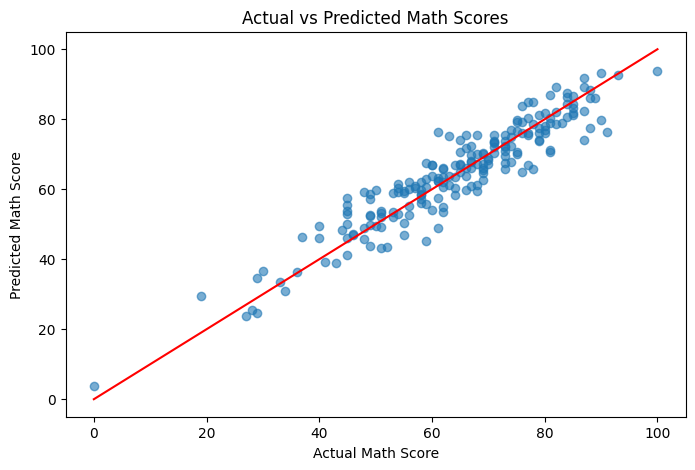

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual Math Score")
plt.ylabel("Predicted Math Score")
plt.title("Actual vs Predicted Math Scores")

plt.plot([0, 100], [0, 100], color="red")

plt.show()